In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [36]:
#name = Prakhar Singh
#adm_no. = 2026B15310387
#room_no. = RJ-107
#sl_no. = 02

from google.colab import files

uploaded = files.upload()

df = pd.read_csv("creditcard.csv")

df.head()

Saving creditcard.csv to creditcard (1).csv


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [38]:
print("frist 5 transactions")
print(df.head())

print("\ndatasetinfo")
df.info()

print("\ncolumnname")
print(df.columns.tolist())

print("\nstatssummary")
print(df.describe())

frist 5 transactions
   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

        V26

In [39]:
total_transactions = len(df)

fraud_count = (df["Class"] == 1).sum()
normal_count = (df["Class"] == 0).sum()

fraud_percentage = (fraud_count / total_transactions) * 100
normal_percentage = (normal_count / total_transactions) * 100

duplicate_count = df.duplicated().sum()
missing_count = df.isnull().sum().sum()

print(" DATA AUDIT REPORT ")

print("Total Transactions:", total_transactions)
print("Normal Transactions:", normal_count)
print("Fraudulent Transactions:", fraud_count)

print("Normal Percentage:", round(normal_percentage, 4))
print("Fraud Percentage:", round(fraud_percentage, 4))

print("Duplicate Rows:", duplicate_count)
print("Missing Values:", missing_count)

print("\nTEMPORAL COVERAGE")

print("Starting Time:", df["Time"].min())
print("Ending Time:", df["Time"].max())


 DATA AUDIT REPORT 
Total Transactions: 284807
Normal Transactions: 284315
Fraudulent Transactions: 492
Normal Percentage: 99.8273
Fraud Percentage: 0.1727
Duplicate Rows: 1081
Missing Values: 0

TEMPORAL COVERAGE
Starting Time: 0.0
Ending Time: 172792.0


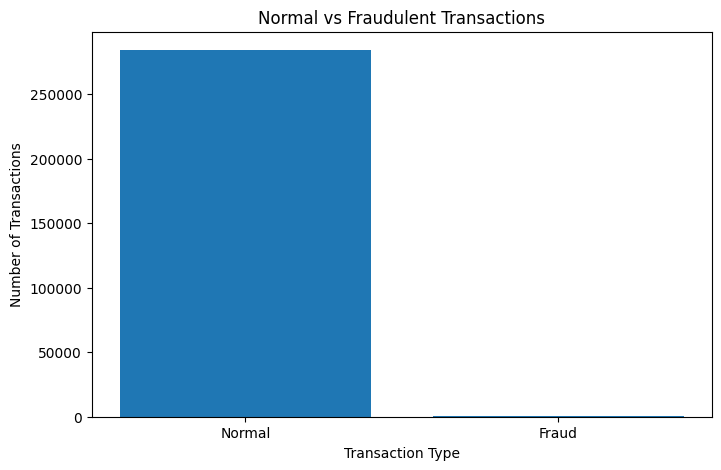

Class Distribution:
Class
0    284315
1       492
Name: count, dtype: int64


In [40]:
class_counts = df["Class"].value_counts().sort_index()

plt.figure(figsize=(8, 5))

plt.bar(
    ["Normal", "Fraud"],
    class_counts.values
)

plt.title("Normal vs Fraudulent Transactions")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")

plt.show()

print("Class Distribution:")
print(class_counts)

In [41]:
amounts = df["Amount"].to_numpy()

mean_amount = np.mean(amounts)
median_amount = np.median(amounts)

std_amount = np.std(amounts)

minimum_amount = np.min(amounts)
maximum_amount = np.max(amounts)

q1 = np.percentile(amounts, 25)
q2 = np.percentile(amounts, 50)
q3 = np.percentile(amounts, 75)

iqr = q3 - q1

print("========== AMOUNT STATISTICS ==========")

print("Mean:", mean_amount)
print("Median:", median_amount)
print("Standard Deviation:", std_amount)

print("Minimum:", minimum_amount)
print("Maximum:", maximum_amount)

print("Q1:", q1)
print("Q2:", q2)
print("Q3:", q3)

print("IQR:", iqr)

print("=======================================")

========== AMOUNT STATISTICS ==========
Mean: 88.34961925093134
Median: 22.0
Standard Deviation: 250.1196701352354
Minimum: 0.0
Maximum: 25691.16
Q1: 5.6
Q2: 22.0
Q3: 77.16499999999999
IQR: 71.565


In [42]:
median = np.median(amounts)

mad = np.median(np.abs(amounts - median))

if mad > 0:

    robust_z_scores = (
        0.6745 * (amounts - median) / mad
    )

    df["Robust_Z"] = robust_z_scores

    df["Amount_Anomaly"] = (
        np.abs(df["Robust_Z"]) > 3.5
    ).astype(int)

else:

    df["Robust_Z"] = 0
    df["Amount_Anomaly"] = 0

print("MAD:", mad)

print(
    "Potential amount anomalies:",
    df["Amount_Anomaly"].sum()
)

MAD: 20.22
Potential amount anomalies: 46571


NORMAL TRANSACTIONS
count    284315.000000
mean         88.291022
std         250.105092
min           0.000000
25%           5.650000
50%          22.000000
75%          77.050000
max       25691.160000
Name: Amount, dtype: float64

FRAUDULENT TRANSACTIONS
count     492.000000
mean      122.211321
std       256.683288
min         0.000000
25%         1.000000
50%         9.250000
75%       105.890000
max      2125.870000
Name: Amount, dtype: float64


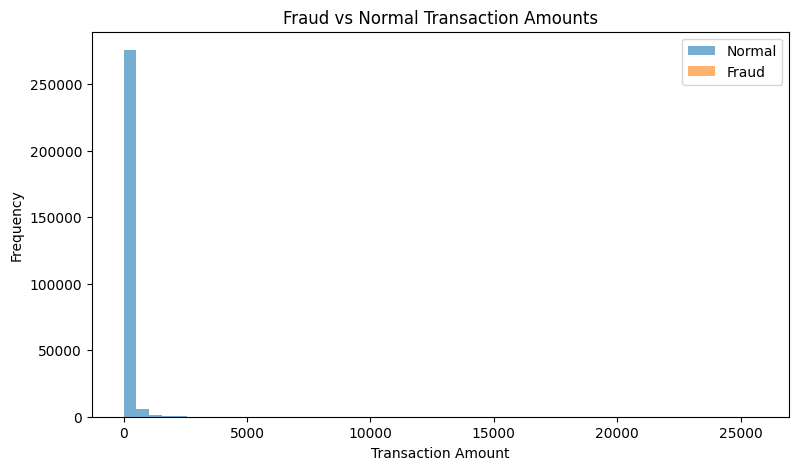

In [43]:
normal_amounts = df[df["Class"] == 0]["Amount"]
fraud_amounts = df[df["Class"] == 1]["Amount"]

print("NORMAL TRANSACTIONS")

print(normal_amounts.describe())

print("\nFRAUDULENT TRANSACTIONS")

print(fraud_amounts.describe())

plt.figure(figsize=(9, 5))

plt.hist(
    normal_amounts,
    bins=50,
    alpha=0.6,
    label="Normal"
)

plt.hist(
    fraud_amounts,
    bins=50,
    alpha=0.6,
    label="Fraud"
)

plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")

plt.title("Fraud vs Normal Transaction Amounts")

plt.legend()
plt.show()

In [44]:


df = df.sort_values("Time").reset_index(drop=True)

time_index = pd.to_timedelta(df["Time"], unit="s")

df["Time_Gap"] = df["Time"].diff().fillna(0)

transaction_series = pd.Series(
    1,
    index=time_index
)

df["Velocity_1H"] = (
    transaction_series
    .rolling("1h", closed="left")
    .sum()
    .fillna(0)
    .to_numpy()
)

amount_series = pd.Series(
    df["Amount"].to_numpy(),
    index=time_index
)

df["Rolling_Mean_Amount_1H"] = (
    amount_series
    .rolling("1h", closed="left")
    .mean()
    .fillna(0)
    .to_numpy()
)

print("Feature engineering completed!")

print(
    df[
        [
            "Time",
            "Amount",
            "Time_Gap",
            "Velocity_1H",
            "Rolling_Mean_Amount_1H"
        ]
    ].head(10)
)

Feature engineering completed!
   Time  Amount  Time_Gap  Velocity_1H  Rolling_Mean_Amount_1H
0   0.0  149.62       0.0          0.0                0.000000
1   0.0    2.69       0.0          0.0                0.000000
2   1.0  378.66       1.0          2.0               76.155000
3   1.0  123.50       0.0          2.0               76.155000
4   2.0   69.99       1.0          4.0              163.617500
5   2.0    3.67       0.0          4.0              163.617500
6   4.0    4.99       2.0          6.0              121.355000
7   7.0   40.80       3.0          7.0              104.731429
8   7.0   93.20       0.0          7.0              104.731429
9   9.0    3.68       2.0          9.0               96.346667


In [45]:
df["Amount_Segment"] = pd.qcut(
    df["Amount"],
    q=4,
    duplicates="drop"
)

segment_analysis = df.groupby(
    "Amount_Segment",
    observed=False
).agg(
    Total_Transactions=("Class", "count"),
    Fraud_Transactions=("Class", "sum"),
    Average_Amount=("Amount", "mean")
)

segment_analysis["Fraud_Rate_Percent"] = (
    segment_analysis["Fraud_Transactions"] /
    segment_analysis["Total_Transactions"] * 100
)

print(segment_analysis)

                    Total_Transactions  Fraud_Transactions  Average_Amount  \
Amount_Segment                                                               
(-0.001, 5.6]                    71241                 224        2.029851   
(5.6, 22.0]                      71402                  47       12.628029   
(22.0, 77.165]                   70962                  47       44.021500   
(77.165, 25691.16]               71202                 174      294.829656   

                    Fraud_Rate_Percent  
Amount_Segment                          
(-0.001, 5.6]                 0.314426  
(5.6, 22.0]                   0.065824  
(22.0, 77.165]                0.066233  
(77.165, 25691.16]            0.244375  


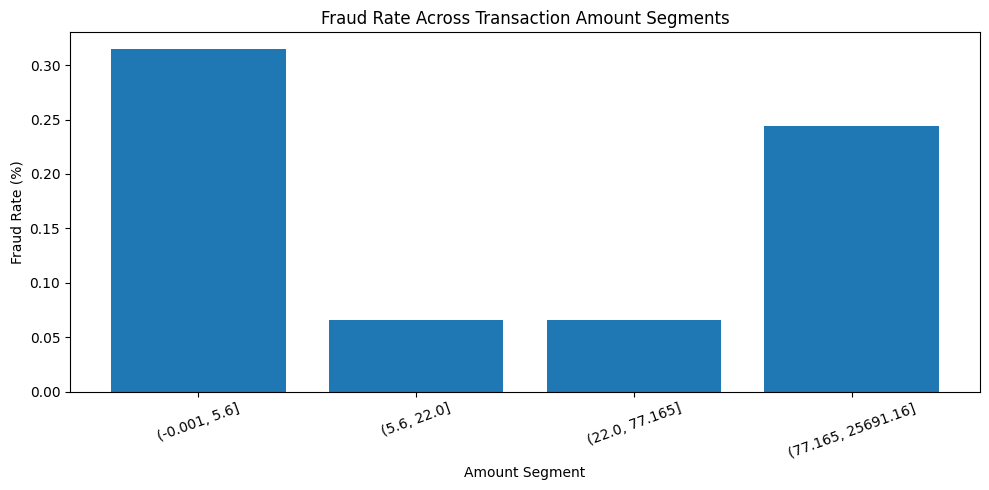

In [46]:
plt.figure(figsize=(10, 5))

plt.bar(
    segment_analysis.index.astype(str),
    segment_analysis["Fraud_Rate_Percent"]
)

plt.title("Fraud Rate Across Transaction Amount Segments")

plt.xlabel("Amount Segment")
plt.ylabel("Fraud Rate (%)")

plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

In [47]:
df = df.sort_values("Time").reset_index(drop=True)

split_index = int(len(df) * 0.70)

train = df.iloc[:split_index].copy()

test = df.iloc[split_index:].copy()

print("Training Transactions:", len(train))
print("Testing Transactions:", len(test))

print("Training End Time:", train["Time"].max())
print("Testing Start Time:", test["Time"].min())

Training Transactions: 199364
Testing Transactions: 85443
Training End Time: 132928.0
Testing Start Time: 132929.0


In [48]:
train_median = np.median(train["Amount"])

train_mad = np.median(
    np.abs(train["Amount"] - train_median)
)

if train_mad > 0:

    df["Robust_Z"] = (
        0.6745 *
        (df["Amount"] - train_median) /
        train_mad
    )

else:

    df["Robust_Z"] = 0



velocity_threshold = np.percentile(
    train["Velocity_1H"],
    99.5
)

print("Training Median:", train_median)
print("Training MAD:", train_mad)

print(
    "99.5th percentile velocity:",
    velocity_threshold
)

Training Median: 23.0
Training MAD: 21.21
99.5th percentile velocity: 10483.0


In [49]:


amount_score = np.abs(df["Robust_Z"])



if velocity_threshold > 0:

    velocity_score = (
        3.5 * df["Velocity_1H"] /
        velocity_threshold
    )

else:

    velocity_score = np.zeros(len(df))



df["Anomaly_Score"] = np.maximum(
    amount_score,
    velocity_score
)



df["Predicted_Fraud"] = (
    df["Anomaly_Score"] >= 3.5
).astype(int)

print("Anomaly detection completed!")

print(
    "Flagged transactions:",
    df["Predicted_Fraud"].sum()
)

Anomaly detection completed!
Flagged transactions: 45640


In [50]:


test = df.iloc[split_index:].copy()

actual = test["Class"].to_numpy()

predicted = test["Predicted_Fraud"].to_numpy()


TP = np.sum((actual == 1) & (predicted == 1))

TN = np.sum((actual == 0) & (predicted == 0))

FP = np.sum((actual == 0) & (predicted == 1))

FN = np.sum((actual == 1) & (predicted == 0))


precision = TP / (TP + FP) if (TP + FP) > 0 else 0

recall = TP / (TP + FN) if (TP + FN) > 0 else 0

accuracy = (
    (TP + TN) / len(actual)
    if len(actual) > 0 else 0
)

false_positive_rate = (
    FP / (FP + TN)
    if (FP + TN) > 0 else 0
)

print("========== MODEL EVALUATION ==========")

print("True Positives:", TP)
print("True Negatives:", TN)
print("False Positives:", FP)
print("False Negatives:", FN)

print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("Accuracy:", round(accuracy, 4))

print(
    "False Positive Rate:",
    round(false_positive_rate, 4)
)


========== MODEL EVALUATION ==========
True Positives: 24
True Negatives: 72515
False Positives: 12820
False Negatives: 84
Precision: 0.0019
Recall: 0.2222
Accuracy: 0.849
False Positive Rate: 0.1502


In [51]:
thresholds = [3.5, 4, 5, 6]

results = []

for threshold in thresholds:

    predictions = (
        test["Anomaly_Score"] >= threshold
    ).astype(int).to_numpy()

    TP = np.sum((actual == 1) & (predictions == 1))

    FP = np.sum((actual == 0) & (predictions == 1))

    FN = np.sum((actual == 1) & (predictions == 0))

    TN = np.sum((actual == 0) & (predictions == 0))

    precision = (
        TP / (TP + FP)
        if TP + FP > 0 else 0
    )

    recall = (
        TP / (TP + FN)
        if TP + FN > 0 else 0
    )

    false_positive_rate = (
        FP / (FP + TN)
        if FP + TN > 0 else 0
    )

    results.append({
        "Threshold": threshold,
        "TP": TP,
        "FP": FP,
        "FN": FN,
        "TN": TN,
        "Precision": precision,
        "Recall": recall,
        "False_Positive_Rate": false_positive_rate
    })

threshold_results = pd.DataFrame(results)

print(threshold_results)

   Threshold  TP     FP  FN     TN  Precision    Recall  False_Positive_Rate
0        3.5  24  12820  84  72515   0.001869  0.222222             0.150231
1        4.0  23  11596  85  73739   0.001980  0.212963             0.135888
2        5.0  22   9377  86  75958   0.002341  0.203704             0.109885
3        6.0  20   7857  88  77478   0.002539  0.185185             0.092072


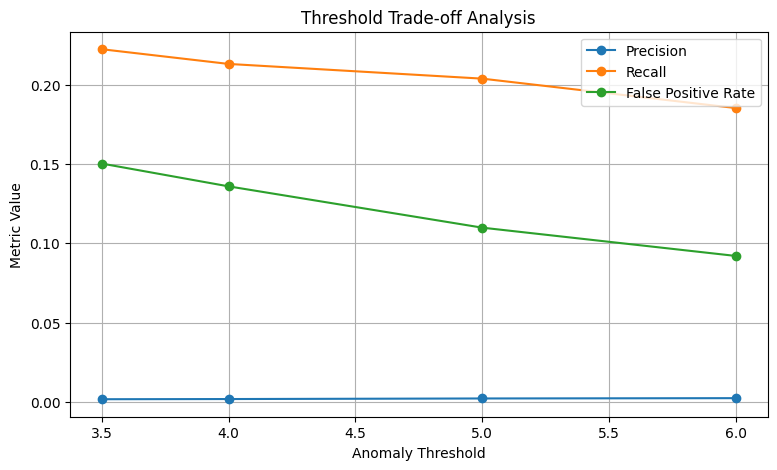

In [52]:
plt.figure(figsize=(9, 5))

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["False_Positive_Rate"],
    marker="o",
    label="False Positive Rate"
)

plt.xlabel("Anomaly Threshold")
plt.ylabel("Metric Value")

plt.title("Threshold Trade-off Analysis")

plt.legend()
plt.grid(True)

plt.show()

In [53]:
FP_COST = 1
FN_COST = 10

threshold_results["Total_Cost"] = (
    threshold_results["FP"] * FP_COST +
    threshold_results["FN"] * FN_COST
)

print(
    threshold_results[
        [
            "Threshold",
            "FP",
            "FN",
            "Total_Cost"
        ]
    ]
)

best_row = threshold_results.loc[
    threshold_results["Total_Cost"].idxmin()
]

print("\nLowest-cost threshold:", best_row["Threshold"])

print("Estimated cost:", best_row["Total_Cost"])

   Threshold     FP  FN  Total_Cost
0        3.5  12820  84       13660
1        4.0  11596  85       12446
2        5.0   9377  86       10237
3        6.0   7857  88        8737

Lowest-cost threshold: 6.0
Estimated cost: 8737.0


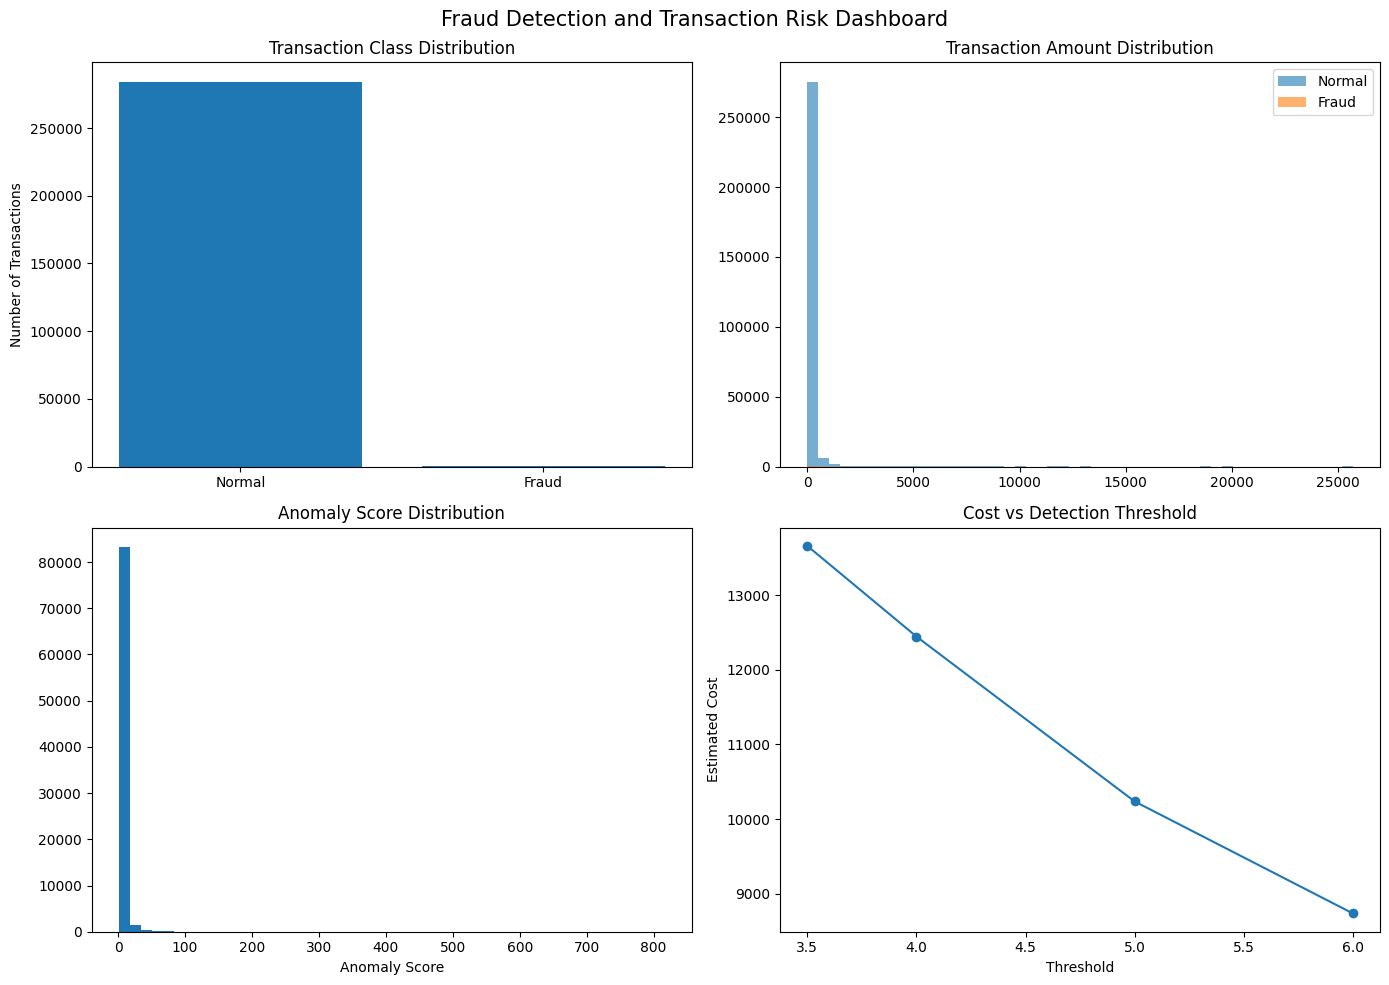

In [54]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))



axes[0, 0].bar(
    ["Normal", "Fraud"],
    [normal_count, fraud_count]
)

axes[0, 0].set_title("Transaction Class Distribution")
axes[0, 0].set_ylabel("Number of Transactions")



axes[0, 1].hist(
    normal_amounts,
    bins=50,
    alpha=0.6,
    label="Normal"
)

axes[0, 1].hist(
    fraud_amounts,
    bins=50,
    alpha=0.6,
    label="Fraud"
)

axes[0, 1].set_title("Transaction Amount Distribution")
axes[0, 1].legend()



axes[1, 0].hist(
    test["Anomaly_Score"],
    bins=50
)

axes[1, 0].set_title("Anomaly Score Distribution")
axes[1, 0].set_xlabel("Anomaly Score")



axes[1, 1].plot(
    threshold_results["Threshold"],
    threshold_results["Total_Cost"],
    marker="o"
)

axes[1, 1].set_title("Cost vs Detection Threshold")
axes[1, 1].set_xlabel("Threshold")
axes[1, 1].set_ylabel("Estimated Cost")

plt.suptitle(
    "Fraud Detection and Transaction Risk Dashboard",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [55]:
feature_columns = [
    "Time",
    "Amount",
    "Time_Gap",
    "Velocity_1H",
    "Rolling_Mean_Amount_1H",
    "Robust_Z",
    "Anomaly_Score",
    "Amount_Anomaly",
    "Predicted_Fraud",
    "Class"
]

feature_table = df[feature_columns].copy()

print("FINAL FEATURE TABLE")

print(feature_table.head(10))

print("\nFeature table shape:")
print(feature_table.shape)

FINAL FEATURE TABLE
   Time  Amount  Time_Gap  Velocity_1H  Rolling_Mean_Amount_1H   Robust_Z  \
0   0.0  149.62       0.0          0.0                0.000000   4.026647   
1   0.0    2.69       0.0          0.0                0.000000  -0.645879   
2   1.0  378.66       1.0          2.0               76.155000  11.310357   
3   1.0  123.50       0.0          2.0               76.155000   3.196004   
4   2.0   69.99       1.0          4.0              163.617500   1.494331   
5   2.0    3.67       0.0          4.0              163.617500  -0.614714   
6   4.0    4.99       2.0          6.0              121.355000  -0.572737   
7   7.0   40.80       3.0          7.0              104.731429   0.566058   
8   7.0   93.20       0.0          7.0              104.731429   2.232433   
9   9.0    3.68       2.0          9.0               96.346667  -0.614396   

   Anomaly_Score  Amount_Anomaly  Predicted_Fraud  Class  
0       4.026647               1                1      0  
1       0.6458

In [56]:
report = f"""
FRAUD DETECTION AND TRANSACTION ANOMALY ANALYSIS

1. PROJECT OVERVIEW

This project analyse anonymised credit card transactions by
use statistical methods and rule-based anomalydetection.

2. DATASET AUDIT

Total transactions: {total_transactions}

Normal transactions: {normal_count}

Fraudulent transactions: {fraud_count}

Fraud percentage: {fraud_percentage:.4f}%

Duplicate rows: {duplicate_count}

Missing values: {missing_count}

3. STATISTICAL ANALYSIS

Mean transaction amount: {mean_amount:.2f}

Median transaction amount: {median_amount:.2f}

Standard deviation: {std_amount:.2f}

First quartile: {q1:.2f}

Third quartile: {q3:.2f}

Interquartile range: {iqr:.2f}

4. ANOMALY DETECTION

The project use robust Z-scores and transaction velocity
to identify the unusual transaction behaviour.

5. MODEL EVALUATION

Precision: {precision:.4f}

Recall: {recall:.4f}

Accuracy: {accuracy:.4f}

False positive rate: {false_positive_rate:.4f}

6. TIME-BASED VALIDATION

The dataset was sorted chronologically.

The first 70 percent us used for development,
and the remaining 30 percent was used for testing.

7. COST ANALYSIS

False positive cost assumption: 1 unit.

False negative cost assumption: 10 units.

Lowest-cost threshold: {best_row['Threshold']}

Estimated cost: {best_row['Total_Cost']}

8. PRIVACY AND LIMITATIONS

The dataset contains anonymised transaction features.

It does not contain customer identifiers, account
identifiers or merchant categories.

Therefore, customer-specific transaction patterns
and merchant-specific fraud rates cannot be calculated.

The system uses global transaction velocity instead.

The dataset not represent current real-world
fraud patterns or all banking customers.

Anomaly detection flags unusual transactions.
It does not establish that a transaction is fraudulent.

The cost values are illustrative assumptions.

9. CONCLUSION

This project demonstrates how Python, Pandas, NumPy
and Matplotlib can be used to audit financial data,
engineer statistical features, identify anomalies,
and evaluate fraud-screening rules.

The system intended as a preliminary risk-screening
workflow and not as a production banking fraud system.
"""

print(report)


FRAUD DETECTION AND TRANSACTION ANOMALY ANALYSIS

1. PROJECT OVERVIEW

This project analyse anonymised credit card transactions by
use statistical methods and rule-based anomalydetection.

2. DATASET AUDIT

Total transactions: 284807

Normal transactions: 284315

Fraudulent transactions: 492

Fraud percentage: 0.1727%

Duplicate rows: 1081

Missing values: 0

3. STATISTICAL ANALYSIS

Mean transaction amount: 88.35

Median transaction amount: 22.00

Standard deviation: 250.12

First quartile: 5.60

Third quartile: 77.16

Interquartile range: 71.56

4. ANOMALY DETECTION

The project use robust Z-scores and transaction velocity
to identify the unusual transaction behaviour.

5. MODEL EVALUATION

Precision: 0.0025

Recall: 0.1852

Accuracy: 0.8490

False positive rate: 0.0921

6. TIME-BASED VALIDATION

The dataset was sorted chronologically.

The first 70 percent us used for development,
and the remaining 30 percent was used for testing.

7. COST ANALYSIS

False positive cost assumption: 

In [59]:
# Saving audited dataset

df.to_csv(
    "audited_transactions.csv",
    index=False
)

# Savingfeature table

feature_table.to_csv(
    "transaction_feature_table.csv",
    index=False
)

# Saving threshold analysis

threshold_results.to_csv(
    "threshold_analysis.csv",
    index=False
)

# Saving final report

with open(
    "fraud_detection_final_report.txt",
    "w"
) as file:

    file.write(report)


In [60]:
from google.colab import files

files.download("audited_transactions.csv")

files.download("transaction_feature_table.csv")

files.download("threshold_analysis.csv")

files.download("fraud_detection_final_report.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>